In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
csv_path = Path("d:/fake review detection/Preprocessed Fake Reviews Detection Dataset.csv")

if not csv_path.exists():
    csv_path = Path.cwd() / "Preprocessed Fake Reviews Detection Dataset.csv"

df = pd.read_csv(csv_path)
df.head(100)

,Unnamed: 0,category,rating,label,text_
0,0,Home_and_Kitchen_5,5,1,love well made sturdi comfort i love veri pretti
1,1,Home_and_Kitchen_5,5,1,love great upgrad origin i 've mine coupl year
2,2,Home_and_Kitchen_5,5,1,thi pillow save back i love look feel pillow
3,3,Home_and_Kitchen_5,1,1,miss inform use great product price i
4,4,Home_and_Kitchen_5,5,1,veri nice set good qualiti we set two month
...,...,...,...,...,...
95,95,Home_and_Kitchen_5,2,0,these weak they bare bring air
96,96,Home_and_Kitchen_5,5,0,great set glass good qualiti comfort handl
97,97,Home_and_Kitchen_5,4,0,it feel cool touch super hard
98,98,Home_and_Kitchen_5,5,0,so cute made well grand daughter love


In [5]:
df.shape

(40432, 5)

In [3]:
df.isnull().sum()

Unnamed: 0    0
category      0
rating        0
label         0
text_         1
dtype: int64

In [4]:
df["text_"] = df["text_"].fillna("")

def token(text):
    tokens = []
    for i in text.split():
        tokens.append(i)
    return tokens

df["tokens"] = df["text_"].apply(token)
df["tokens"].head()

0    [love, well, made, sturdi, comfort, i, love, v...
1    [love, great, upgrad, origin, i, 've, mine, co...
2    [thi, pillow, save, back, i, love, look, feel,...
3        [miss, inform, use, great, product, price, i]
4    [veri, nice, set, good, qualiti, we, set, two,...
Name: tokens, dtype: object

In [5]:
"""def lowercaing(text):
    tokens1=[]
    for i in text.upper():
        tokens1.append(i)
    return tokens1
df["tokens1"] = df["text_"].apply(lowercaing)
df["tokens1"].head()"""

'def lowercaing(text):\n    tokens1=[]\n    for i in text.upper():\n        tokens1.append(i)\n    return tokens1\ndf["tokens1"] = df["text_"].apply(lowercaing)\ndf["tokens1"].head()'

In [6]:
import string 
string.punctuation
exclude=string.punctuation
def remove_punctuation(text):
    for char in exclude:
        text=text.replace(char,"")
    return text
df["new_text"]=df["text_"].apply(remove_punctuation)
df["new_text"].head(20)
    

0      love well made sturdi comfort i love veri pretti
1         love great upgrad origin i ve mine coupl year
2          thi pillow save back i love look feel pillow
3                 miss inform use great product price i
4           veri nice set good qualiti we set two month
5                 i want differ flavor but they are not
6           they perfect touch thing i wish littl space
7     these done fit well look great i love smooth e...
8       great big number easi read thing i nt like size
9            my son love comfort well made we also babi
10         a advertis 5th one i ve the problem s realli
11          veri handi one kid tool includ packag i one
12             did someon say  orient  it great product
13    these flimsi they qualiti would expect piec fu...
14        make may tea stir the problem s kind hard put
15     absolut ador and excel price we wooden one month
16     love perfect size entir famili veri good qualiti
17    these look beauti nice the problem s reall

In [7]:
!pip install symspellpy

In [8]:
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

def stem_word(text):
    return " ".join([ps.stem(word) for word in text.split()])

df["new_text"] = df["new_text"].apply(stem_word)

In [9]:
df["new_text"].head(20)

0      love well made sturdi comfort i love veri pretti
1         love great upgrad origin i ve mine coupl year
2          thi pillow save back i love look feel pillow
3                 miss inform use great product price i
4           veri nice set good qualiti we set two month
5                 i want differ flavor but they are not
6           they perfect touch thing i wish littl space
7     these done fit well look great i love smooth e...
8       great big number easi read thing i nt like size
9            my son love comfort well made we also babi
10          a adverti 5th one i ve the problem s realli
11          veri handi one kid tool includ packag i one
12               did someon say orient it great product
13    these flimsi they qualiti would expect piec fu...
14        make may tea stir the problem s kind hard put
15     absolut ador and excel price we wooden one month
16     love perfect size entir famili veri good qualiti
17    these look beauti nice the problem s reall

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_tfidf = tfidf.fit_transform(df["new_text"].fillna(""))
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
)

print(tfidf_df.head())

   105   12   14  1st   25  2nd  32608  32608 bulb  32d  32oz  ...  youngest  \
0  0.0  0.0  0.0  0.0  0.0  0.0    0.0         0.0  0.0   0.0  ...       0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0    0.0         0.0  0.0   0.0  ...       0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0    0.0         0.0  0.0   0.0  ...       0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0    0.0         0.0  0.0   0.0  ...       0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0    0.0         0.0  0.0   0.0  ...       0.0   

   your  youtub   yr  yr old  zero  zip  zipper  zombi  zoom  
0   0.0     0.0  0.0     0.0   0.0  0.0     0.0    0.0   0.0  
1   0.0     0.0  0.0     0.0   0.0  0.0     0.0    0.0   0.0  
2   0.0     0.0  0.0     0.0   0.0  0.0     0.0    0.0   0.0  
3   0.0     0.0  0.0     0.0   0.0  0.0     0.0    0.0   0.0  
4   0.0     0.0  0.0     0.0   0.0  0.0     0.0    0.0   0.0  

[5 rows x 5000 columns]


In [11]:
print("TF-IDF Shape:", X_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))
print(df.shape)

TF-IDF Shape: (40432, 5000)
Number of features: 5000
(40432, 7)


In [12]:
feature_names = tfidf.get_feature_names_out()

for i in range(10):
    print(feature_names[i])

105
12
14
1st
25
2nd
32608
32608 bulb
32d
32oz


In [13]:
X = df[['text_', 'rating']]
y = df['label']
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_text = tfidf.fit_transform(X_train['text_'].fillna(''))
X_test_text = tfidf.transform(X_test['text_'].fillna(''))

In [15]:
from scipy.sparse import hstack, csr_matrix

X_train_final = hstack([
    X_train_text,
    csr_matrix(X_train[['rating']].values)
])

X_test_final = hstack([
    X_test_text,
    csr_matrix(X_test[['rating']].values)
])

In [16]:
print("X_train:", X_train_final.shape)
print("X_test:", X_test_final.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32345, 5001)
X_test: (8087, 5001)
y_train: (32345,)
y_test: (8087,)


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_model.fit(X_train_final, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [18]:
y_pred = rf_model.predict(X_test_final)

In [19]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8804253740571287

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      4044
           1       0.89      0.86      0.88      4043

    accuracy                           0.88      8087
   macro avg       0.88      0.88      0.88      8087
weighted avg       0.88      0.88      0.88      8087


Confusion Matrix:
[[3627  417]
 [ 550 3493]]


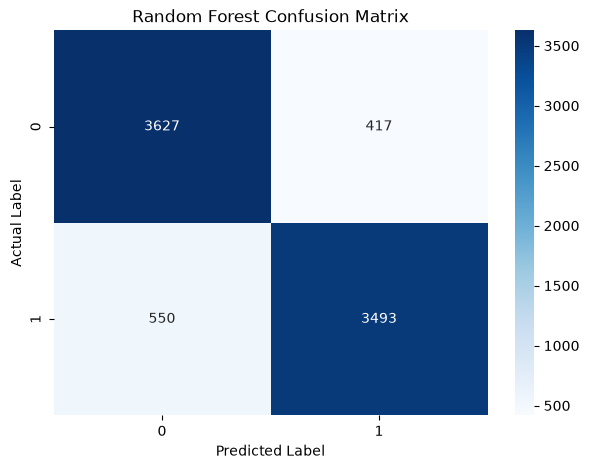

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.show()

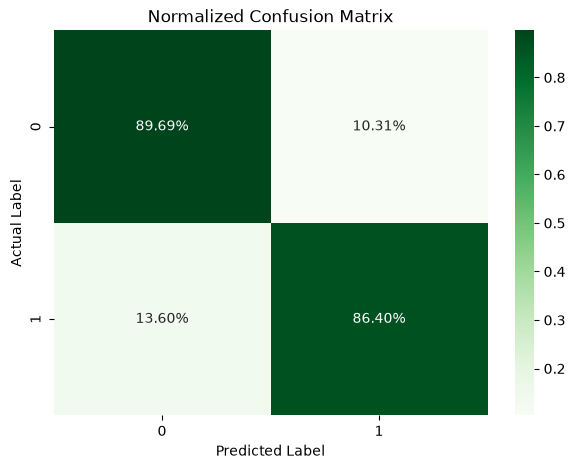

In [21]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='.2%',
    cmap='Greens',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Normalized Confusion Matrix")
plt.show()

In [22]:
!pip install -q xgboost

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [23]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_final, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
y_pred_xgb = xgb_model.predict(X_test_final)

In [25]:
print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.8464201805366638

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.85      4044
           1       0.88      0.80      0.84      4043

    accuracy                           0.85      8087
   macro avg       0.85      0.85      0.85      8087
weighted avg       0.85      0.85      0.85      8087



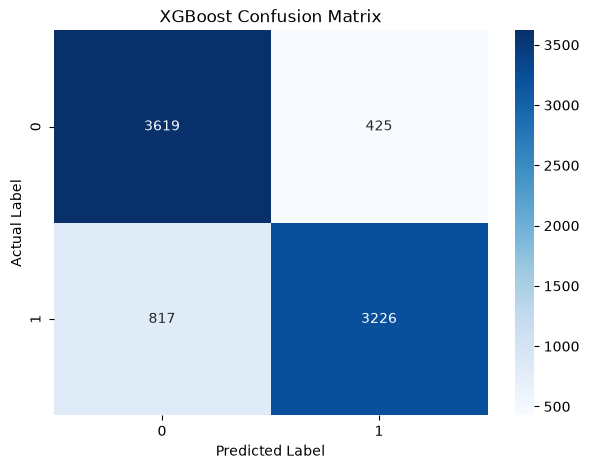

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=xgb_model.classes_,
    yticklabels=xgb_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("XGBoost Confusion Matrix")

plt.show()

In [27]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_xgb)
    ]
})

print(results)

           Model  Accuracy
0  Random Forest  0.880425
1        XGBoost  0.846420


In [ ]:
import pickle
pickle.dump(tfidf, open('tfidf_vectorizer.pkl', 'wb'))
pickle.dump(rf_model, open('random_forest_model.pkl', 'wb'))
